# manasight 02: Exploratory Data Analysis

**Hypothesis H0:** a card's color can be predicted from its art at all.

Before any model, this notebook looks at the pictures and sets the floor every model has to beat:
pure chance and "always guess the biggest class". What we find decides the cleanup and the preprocessing.

Sections:
1. Load data
2. Odd sets: pictures that are not card paintings
3. The floor: chance and majority baselines
4. Palette preview: do the colors look different on average?
5. Type preview
6. Picture shapes
7. Look-alike check between test and train
8. Change over time
9. Artists
10. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, JUNK_SETS, load_cards
from manasight.eda import load_thumbnails, brightness_and_saturation, gray_fingerprints

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # paintings: jpeg keeps the notebook small

def show_grid(picks, columns, title):
    # a grid of pictures with the set and card name above each one
    rows = int(np.ceil(len(picks) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(2 * columns, 1.7 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, card in zip(axes.flat, picks.itertuples()):
        ax.imshow(Image.open(card.path))
        ax.set_title(f"{card.set}: {card.name[:16]}", fontsize=8)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

## 1. Load data

`cards` is the table from notebook 01. `thumbs` holds a tiny 32x32 version of every picture: small enough to keep
all 48,278 in memory, and enough for averages and comparisons. (The first run opens every image, a few minutes.
After that it loads from a saved file.)

In [2]:
cards = load_cards()
thumbs, sizes = load_thumbnails(cards)
print(f"pictures: {len(cards):,}")
print("thumbs:", thumbs.shape, " sizes:", sizes.shape)

pictures: 48,278
thumbs: (48278, 32, 32, 3)  sizes: (48278, 2)


## 2. Odd sets: pictures that are not card paintings

The sample grid in notebook 01 showed a few pictures with lettering and collage. Where do they come from?
One quick way to find strange sets: average **saturation** per set (0 = grey, 1 = vivid).
A set of grey pictures stands out.

In [3]:
brightness, saturation = brightness_and_saturation(thumbs)
cards["brightness"] = brightness
cards["saturation"] = saturation
cards["year"] = cards.released_at.str[:4].astype(int)

per_set = cards.groupby(["set", "set_name"]).agg(pictures=("saturation", "size"),
                                                 saturation=("saturation", "mean"))
per_set = per_set[per_set.pictures >= 30].sort_values("saturation")
print("least colorful sets:")
print(per_set.head(5).round(3).to_string())
print(f"\naverage over all pictures: {cards.saturation.mean():.3f}")

least colorful sets:
                               pictures  saturation
set set_name                                       
dbl Innistrad: Double Feature       532       0.095
mb2 Mystery Booster 2               164       0.134
otp Breaking News                    65       0.206
all Alliances                       199       0.214
vow Innistrad: Crimson Vow          265       0.217

average over all pictures: 0.348


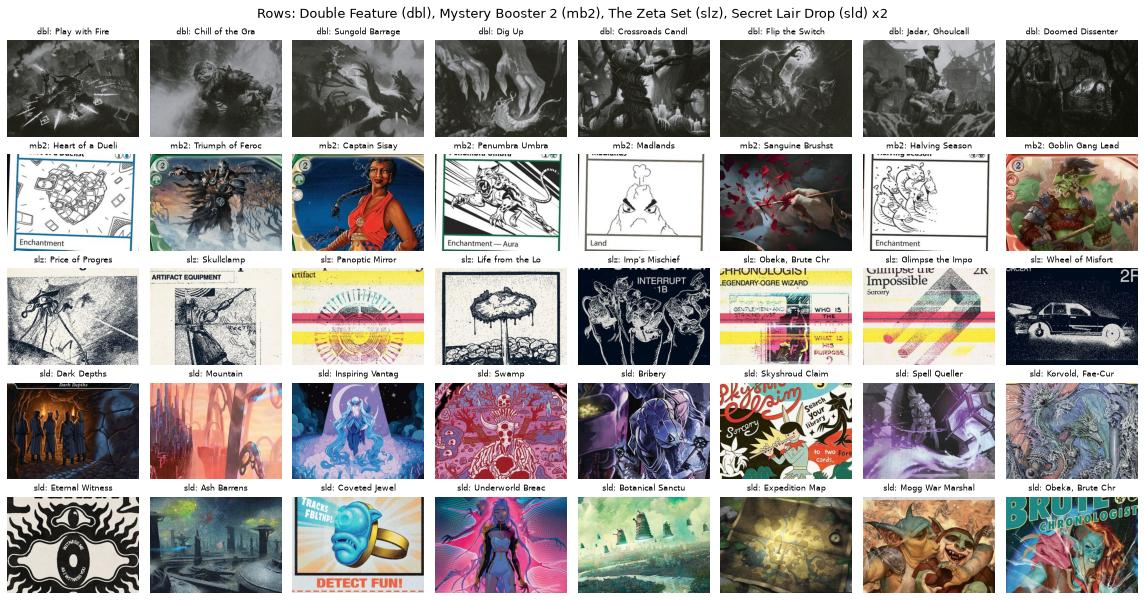

In [4]:
picks = pd.concat([cards[cards.set == "dbl"].sample(8, random_state=3),
                   cards[cards.set == "mb2"].sample(8, random_state=3),
                   cards[cards.set == "slz"].sample(8, random_state=3),
                   cards[cards.set == "sld"].sample(16, random_state=3)])
show_grid(picks, 8, "Rows: Double Feature (dbl), Mystery Booster 2 (mb2), The Zeta Set (slz), Secret Lair Drop (sld) x2")

**Finding:**
- **dbl** (Innistrad: Double Feature): black-and-white reprints. Section 7 confirms they are copies of paintings we already have in color.
- **mb2** (Mystery Booster 2): many test-print sketches, and crops that include the card frame.
- **slz** (The Zeta Set): collages of card frames and text, not paintings.
- **sld** (Secret Lair Drop): real art in unusual styles (pop art, comics, some lettering). Different, but still pictures made for that card.

**Decision:** dbl, mb2 and slz are left out of every split (`JUNK_SETS` in `data.py`; `load_cards()` marks them
`is_junk` and "removed"). Secret Lair stays: unusual style is part of the problem, not an error.
None of the 10 test sets is affected, so test results stay comparable with the reference project.

In [5]:
junk = cards[cards.is_junk]
print(f"left out: {len(junk):,} pictures")
print(junk.set_name.value_counts().to_string())
print("\nmain split now:")
print(cards.split.value_counts().to_string())

# from here on: only pictures that are in the main split
main = cards[cards.split.isin(["train", "val", "test"])]
train = main[main.split == "train"]
test = main[main.split == "test"]

left out: 1,075 pictures
set_name
Innistrad: Double Feature    532
The Zeta Set                 379
Mystery Booster 2            164

main split now:
split
train      35383
val         4798
removed     4705
test        3392


## 3. The floor: chance and majority baselines

Two "models" that never look at the picture:
- **Chance:** pick one of the 7 classes at random: 1/7 = 14.3%.
- **Majority:** always answer the biggest class of the training set.

Any real model has to beat these. We report **accuracy** and **macro-F1** (the F1 score of every class, averaged,
so small classes count as much as big ones).

In [6]:
rows = []
for task, classes in (("color", COLOR_CLASSES), ("type", TYPE_CLASSES)):
    biggest = train[task].value_counts().index[0]
    always = [biggest] * len(test)
    rows.append({"task": task,
                 "chance": 1 / len(classes),
                 "majority class": COLOR_NAMES.get(biggest, biggest),
                 "majority accuracy": accuracy_score(test[task], always),
                 "majority macro-F1": f1_score(test[task], always, average="macro", zero_division=0)})
floor = pd.DataFrame(rows).set_index("task")
floor.round(3)

,chance,majority class,majority accuracy,majority macro-F1
task,,,,
color,0.143,Multicolor,0.202,0.048
type,0.143,Creature,0.499,0.095


**Finding:** for color the floor is low: 14% by chance, 20% by always saying Multicolor.
For type, always saying "Creature" already scores 50% accuracy but only 0.10 macro-F1.

**Decision:** a type model's accuracy means little until it is well above 50%; macro-F1 is the number to watch there.
For reference, the numbers to beat later: color histogram 34.4% and a small from-scratch CNN 36.8% on color
(reference project).

## 4. Palette preview: do the colors look different on average?

The palette idea says red cards look red. A first check without any model: average all pictures of a class
into one "average picture", and compare simple numbers per class:

- **brightness** (0 = black, 1 = full light)
- **saturation** (0 = grey, 1 = vivid)
- **warmth** = average red minus average blue (above 0 = warm tones, below 0 = cool tones)

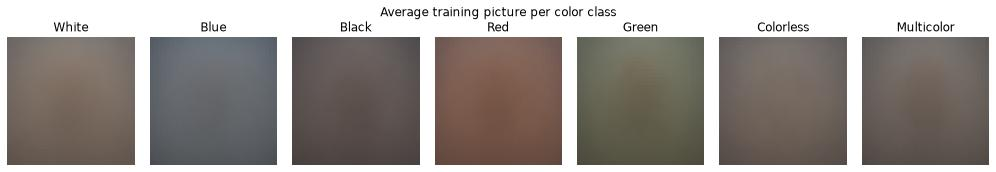

In [7]:
fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
for ax, color in zip(axes, COLOR_CLASSES):
    average_picture = thumbs[(train.color == color).reindex(cards.index, fill_value=False)].mean(axis=0) / 255
    ax.imshow(average_picture)
    ax.set_title(COLOR_NAMES[color])
    ax.axis("off")
plt.suptitle("Average training picture per color class")
plt.tight_layout()
plt.show()

            brightness  saturation  warmth
White            0.501       0.328   0.084
Blue             0.481       0.345  -0.037
Black            0.399       0.326   0.045
Red              0.488       0.422   0.164
Green            0.444       0.345   0.070
Colorless        0.478       0.350   0.063
Multicolor       0.461       0.354   0.054


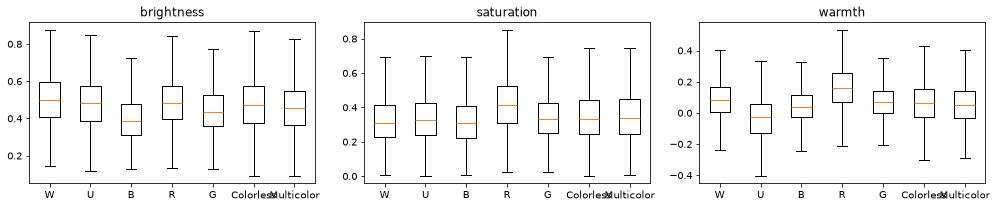

In [8]:
average_rgb = thumbs.astype(np.float32).mean(axis=(1, 2)) / 255      # one (R, G, B) per picture
cards["warmth"] = average_rgb[:, 0] - average_rgb[:, 2]
main = cards[cards.split.isin(["train", "val", "test"])]
train = main[main.split == "train"]
test = main[main.split == "test"]

palette = train.groupby("color")[["brightness", "saturation", "warmth"]].mean().loc[COLOR_CLASSES]
palette.index = [COLOR_NAMES[c] for c in COLOR_CLASSES]
print(palette.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, column in zip(axes, ["brightness", "saturation", "warmth"]):
    groups = [train.loc[train.color == c, column] for c in COLOR_CLASSES]
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(COLOR_CLASSES)
    ax.set_title(column)
plt.tight_layout()
plt.show()

**Finding:** the averages do differ, in the direction the palette idea predicts:
- **Red** is the warmest and the most vivid class.
- **Blue** is the only class with cool tones on average (warmth below 0).
- **Black** is the darkest, **White** the brightest.
- **Green** sits in the middle on these three numbers; Colorless and Multicolor look like a mix of everything.

But the boxes overlap a lot: plenty of red cards are cooler than plenty of blue cards.
So there is a palette signal, and it is far from enough to separate the classes on its own.
This supports H0 (something is predictable) and sets up notebook 03, which measures how far the palette alone gets.

## 5. Type preview

Same numbers per type, and a few pictures of each.

              brightness  saturation  warmth
type                                        
Creature           0.461       0.346   0.062
Planeswalker       0.469       0.318   0.044
Land               0.471       0.359   0.029
Artifact           0.465       0.374   0.069
Enchantment        0.464       0.354   0.068
Instant            0.475       0.363   0.067
Sorcery            0.461       0.365   0.073


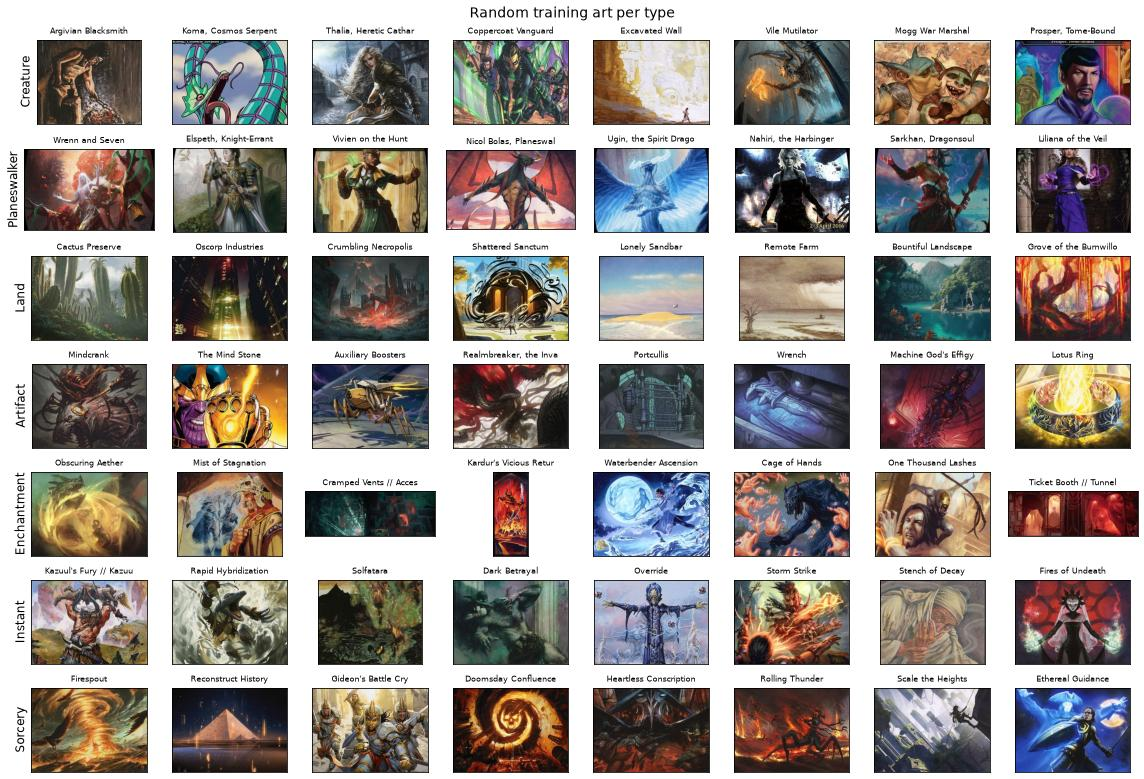

In [9]:
by_type = train.groupby("type")[["brightness", "saturation", "warmth"]].mean().loc[TYPE_CLASSES]
print(by_type.round(3).to_string())

picks = pd.concat([train[train.type == t].sample(8, random_state=5) for t in TYPE_CLASSES])
fig, axes = plt.subplots(7, 8, figsize=(16, 11))
for ax, card in zip(axes.flat, picks.itertuples()):
    ax.imshow(Image.open(card.path))
    ax.set_title(card.name[:22], fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
for row, name in enumerate(TYPE_CLASSES):
    axes[row, 0].set_ylabel(name, fontsize=12)
plt.suptitle("Random training art per type", fontsize=14)
plt.tight_layout()
plt.show()

**Finding:** brightness, saturation and warmth are nearly the same for every type (lands are slightly cooler: skies
and water). The palette says very little about type.
If type is visible in art, it is through *what is in the picture*: creatures show a figure, lands show a place,
artifacts show an object. Instants and sorceries both show an action or an effect and are hard to tell apart by eye.

This matches the reference project, where a color histogram scored at chance level on type.

## 6. Picture shapes

Models want square input (224x224). Our pictures are not square.

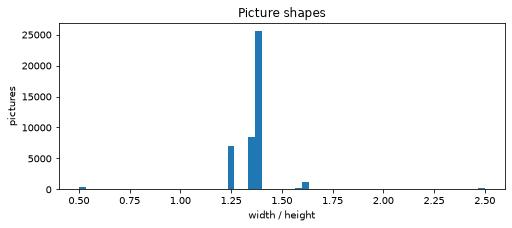

typical shape: 1.37 (width / height)
taller than wide: 422   most common types: {'Enchantment': 278, 'Creature': 80, 'Instant': 33}
very wide (over 1.6): 1,457   most common sets: {'Doctor Who': 158, 'Fallout': 92, 'Final Fantasy Commander': 85}


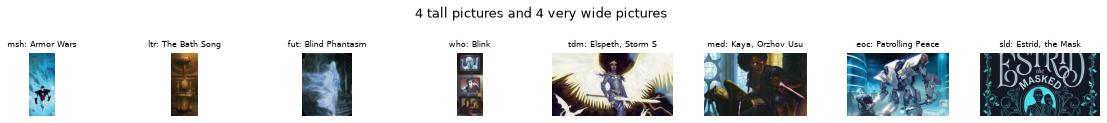

In [10]:
cards["shape"] = sizes[:, 0] / sizes[:, 1]     # width / height
main = cards[cards.split.isin(["train", "val", "test"])]
train = main[main.split == "train"]
test = main[main.split == "test"]

plt.figure(figsize=(8, 3))
plt.hist(main["shape"].clip(0.5, 2.5), bins=60)
plt.xlabel("width / height")
plt.ylabel("pictures")
plt.title("Picture shapes")
plt.show()

tall = main[main["shape"] < 1]
wide = main[main["shape"] > 1.6]
print(f"typical shape: {main['shape'].median():.2f} (width / height)")
print(f"taller than wide: {len(tall):,}   most common types: {tall.type.value_counts().head(3).to_dict()}")
print(f"very wide (over 1.6): {len(wide):,}   most common sets: {wide.set_name.value_counts().head(3).to_dict()}")

show_grid(pd.concat([tall.sample(4, random_state=1), wide.sample(4, random_state=1)]), 8,
          "4 tall pictures and 4 very wide pictures")

**Finding:** almost all art is a landscape rectangle of about 1.37 : 1. About 1% is tall (mostly sagas, a kind of
enchantment) and about 3% is very wide (special borderless printings).

**Decision:** validation and test pictures are resized to 224 on the short side and **center-cropped** to 224x224
(the standard for pretrained models; the main subject is usually in the middle). Training uses a **random** crop
instead, so over many epochs the model also sees the edges.

## 7. Look-alike check between test and train

Notebook 01 removed every other painting of the test cards. One leak could remain: the *same painting* stored under
two different IDs (a re-crop or a recolored copy) on two different cards. We compare every test picture with every
train and val picture using a small grey fingerprint (16x16). Similarity 1 = same picture, 0 = unrelated.

First a sanity check that the fingerprint works: Double Feature (black-and-white copies) against everything else.

In [11]:
fingerprints = gray_fingerprints(thumbs)

is_dbl = (cards.set == "dbl").to_numpy()
similarity = fingerprints[is_dbl] @ fingerprints[~is_dbl].T          # every dbl picture vs every other picture
best = similarity.max(axis=1)
best_match = similarity.argmax(axis=1)
same_name = cards.name.to_numpy()[is_dbl] == cards.name.to_numpy()[~is_dbl][best_match]

print(f"Double Feature pictures with a look-alike above 0.95: {(best > 0.95).mean():.0%}")
print(f"of those, the look-alike is the same card: {same_name[best > 0.95].mean():.0%}")

Double Feature pictures with a look-alike above 0.95: 81%
of those, the look-alike is the same card: 100%


test pictures with a train look-alike above 0.99: 0
test pictures with a train look-alike above 0.97: 0
test pictures with a train look-alike above 0.95: 0
test pictures with a train look-alike above 0.9: 10


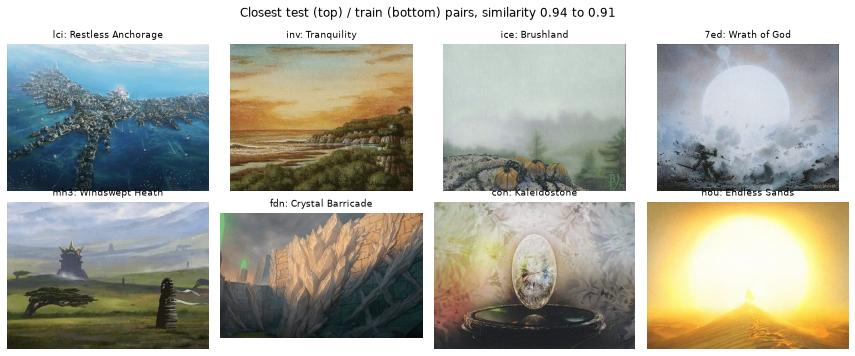

In [12]:
is_test = (cards.split == "test").to_numpy()
is_train = cards.split.isin(["train", "val"]).to_numpy()

similarity = fingerprints[is_test] @ fingerprints[is_train].T        # every test picture vs every train/val picture
best = similarity.max(axis=1)
best_match = similarity.argmax(axis=1)

for threshold in (0.99, 0.97, 0.95, 0.90):
    print(f"test pictures with a train look-alike above {threshold}: {(best > threshold).sum()}")

# the closest pairs, to look at
order = np.argsort(-best)[:4]
test_cards = cards[is_test].iloc[order]
train_cards = cards[is_train].iloc[best_match[order]]
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for column in range(4):
    for row, card in enumerate((test_cards.iloc[column], train_cards.iloc[column])):
        axes[row, column].imshow(Image.open(card.path))
        axes[row, column].set_title(f"{card.set}: {card['name'][:20]}", fontsize=9)
        axes[row, column].axis("off")
plt.suptitle(f"Closest test (top) / train (bottom) pairs, similarity {best[order[0]]:.2f} to {best[order[-1]]:.2f}")
plt.tight_layout()
plt.show()

**Finding:** the fingerprint works: most black-and-white Double Feature pictures find their color original, and it is
always the same card. Between test and train there is **no** look-alike above 0.95. The closest pairs
are different paintings with a similar layout (a horizon, a centered figure).

**Decision:** no extra removal needed. The test set does not leak into training through copied art.

## 8. Change over time

Groundwork for a later question (did the "look" of the colors change over 30 years?).
Here only the basics: brightness and saturation by release year.

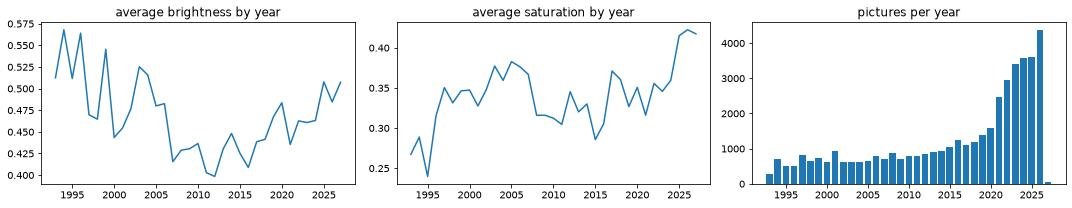

pictures from 2020 or later: 51%


In [13]:
by_year = main.groupby("year")[["brightness", "saturation"]].mean()
counts = main.groupby("year").size()

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].plot(by_year.index, by_year.brightness)
axes[0].set_title("average brightness by year")
axes[1].plot(by_year.index, by_year.saturation)
axes[1].set_title("average saturation by year")
axes[2].bar(counts.index, counts.values)
axes[2].set_title("pictures per year")
plt.tight_layout()
plt.show()

print(f"pictures from 2020 or later: {(main.year >= 2020).mean():.0%}")

**Finding:** the look does change. The earliest years are the brightest and the least vivid (scans of printed
cards), art is darkest around 2010 to 2013, and the most recent years are the most vivid.
Also: recent years dominate the data. Half of all pictures are from 2020 or later, because many more cards are
printed now. (The few pictures dated after today are previewed cards from upcoming sets.)

**Consequence:** a rule like "dark = Black" learned mostly from recent art may not hold for 1994 art.
The test set has 2 sets per era, so notebook 07 can measure this.

## 9. Artists

Groundwork for another later question (does a model partly recognize artists instead of colors?).

artists: 2,208
the 100 busiest artists made 39% of all pictures


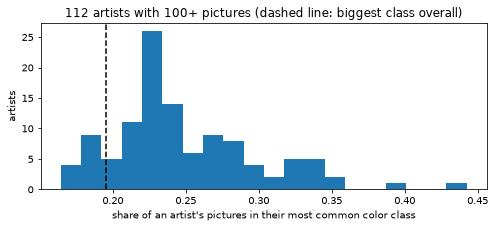

typical artist: 23% in their top class
strongest leanings:
artist
Daniel Ljunggren    0.35
Rebecca Guay        0.39
Piotr Dura          0.44


In [14]:
per_artist = main.artist.value_counts()
print(f"artists: {len(per_artist):,}")
print(f"the 100 busiest artists made {per_artist.head(100).sum() / len(main):.0%} of all pictures")

# for artists with 100+ pictures: how much of their work is in their most common color class?
busy = main[main.artist.isin(per_artist.index[per_artist >= 100])]
mix = pd.crosstab(busy.artist, busy.color, normalize="index")
top_share = mix.max(axis=1).sort_values()

plt.figure(figsize=(8, 3))
plt.hist(top_share, bins=20)
plt.axvline(main.color.value_counts(normalize=True).max(), color="black", linestyle="--")
plt.xlabel("share of an artist's pictures in their most common color class")
plt.ylabel("artists")
plt.title(f"{len(top_share)} artists with 100+ pictures (dashed line: biggest class overall)")
plt.show()

print(f"typical artist: {top_share.median():.0%} in their top class")
print("strongest leanings:")
print(top_share.tail(3).round(2).to_string())

**Finding:** most busy artists paint all colors: a typical one has about a quarter of their work in their top class,
close to what an even spread gives. A few lean clearly toward one class.

**Consequence:** knowing the artist gives away a little about the color, not a lot. The by-artist split from
notebook 01 will tell us how much a model leans on it.

## 10. Summary

| Question | Finding | Decision |
|---|---|---|
| Odd sets | dbl, mb2, slz are not normal card paintings (1,075 pictures) | Left out of every split; Secret Lair stays |
| The floor | Color: chance 14%, majority 20%. Type: majority 50% accuracy, 0.10 macro-F1 | Beat these; watch macro-F1 for type |
| Palette | Red warm and vivid, Blue cool, Black dark, White bright, with big overlap | H0 holds: there is signal. Measure the palette alone in 03 |
| Type | Brightness, saturation and warmth do not differ by type | Type needs content, not palette |
| Shapes | About 1.37 : 1; 1% tall, 3% very wide | Center crop for val/test, random crop for training |
| Look-alikes | No test picture has a copy in train | No extra removal |
| Time | Early art brighter and less vivid; recent years dominate | Per-era scores in 07 |
| Artists | Most paint all colors; a few lean | By-artist split in 07 |

**H0:** supported so far. The classes differ on average even in three simple numbers, so color is not invisible in the
art. How much of it a model can actually use is the next question.

**Next:** 03, the color histogram baseline: how far does the palette alone get?